# **CA-2 ASSIGNMENT CODE**

## **Topic: Exoplanet Detection Using Tree-Based Models and a Hybrid Ensemble Approach**

### **Importing Libraries**

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.metrics import roc_curve, auc

from sklearn.ensemble import VotingClassifier

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(
    "cumulative_2026.01.16_20.39.37.csv",
    comment="#"
)

df

,kepid,kepoi_name,kepler_name,koi_pdisposition,koi_period,koi_period_err1,koi_period_err2,koi_impact,koi_impact_err1,koi_impact_err2,...,koi_slogg_err2,koi_smet,koi_smet_err1,koi_smet_err2,koi_srad,koi_srad_err1,koi_srad_err2,koi_smass,koi_smass_err1,koi_smass_err2
0,10797460,K00752.01,Kepler-227 b,CANDIDATE,9.488036,2.775000e-05,-2.775000e-05,0.146,0.318,-0.146,...,-0.096,0.14,0.15,-0.15,0.927,0.105,-0.061,0.919,0.052,-0.046
1,10797460,K00752.02,Kepler-227 c,CANDIDATE,54.418383,2.479000e-04,-2.479000e-04,0.586,0.059,-0.443,...,-0.096,0.14,0.15,-0.15,0.927,0.105,-0.061,0.919,0.052,-0.046
2,10811496,K00753.01,NaN,CANDIDATE,19.899140,1.494000e-05,-1.494000e-05,0.969,5.126,-0.077,...,-0.176,-0.18,0.30,-0.30,0.868,0.233,-0.078,0.961,0.110,-0.121
3,10848459,K00754.01,NaN,FALSE POSITIVE,1.736952,2.630000e-07,-2.630000e-07,1.276,0.115,-0.092,...,-0.168,-0.52,0.30,-0.30,0.791,0.201,-0.067,0.836,0.093,-0.077
4,10854555,K00755.01,Kepler-664 b,CANDIDATE,2.525592,3.761000e-06,-3.761000e-06,0.701,0.235,-0.478,...,-0.210,0.07,0.25,-0.30,1.046,0.334,-0.133,1.095,0.151,-0.136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9559,10090151,K07985.01,NaN,FALSE POSITIVE,0.527699,1.160000e-07,-1.160000e-07,1.252,0.051,-0.049,...,-0.196,0.14,0.20,-0.30,0.903,0.237,-0.079,1.005,0.084,-0.115
9560,10128825,K07986.01,NaN,CANDIDATE,1.739849,1.780000e-05,-1.780000e-05,0.043,0.423,-0.043,...,-0.224,-0.04,0.25,-0.30,1.031,0.341,-0.114,1.075,0.151,-0.135
9561,10147276,K07987.01,NaN,FALSE POSITIVE,0.681402,2.434000e-06,-2.434000e-06,0.147,0.309,-0.147,...,-0.224,-0.04,0.25,-0.35,1.041,0.341,-0.114,1.104,0.146,-0.162
9562,10155286,K07988.01,NaN,CANDIDATE,333.486169,4.235000e-03,-4.235000e-03,0.214,0.255,-0.214,...,-0.027,0.07,0.10,-0.25,7.824,0.223,-1.896,2.190,0.225,-0.845


In [3]:
df.isnull().sum().sort_values(ascending=False)


koi_teq_err2         9564
koi_teq_err1         9564
kepler_name          6817
koi_steff_err2        483
koi_srad_err2         468
koi_slogg_err1        468
koi_smass_err1        468
koi_steff_err1        468
koi_slogg_err2        468
koi_srad_err1         468
koi_smass_err2        468
koi_period_err1       454
koi_duration_err1     454
koi_duration_err2     454
koi_depth_err2        454
koi_impact_err1       454
koi_period_err2       454
koi_impact_err2       454
koi_depth_err1        454
koi_smet_err2         387
koi_smet_err1         387
koi_smet              386
koi_impact            363
koi_prad              363
koi_depth             363
koi_steff             363
koi_srad              363
koi_slogg             363
koi_smass             363
koi_model_snr         363
koi_prad_err2         363
koi_teq               363
koi_prad_err1         363
koi_insol_err1        321
koi_insol             321
koi_insol_err2        321
kepid                   0
kepoi_name              0
koi_pdisposi

### **Data Preprocessing**

In [4]:
df.drop(
    columns=["koi_teq_err2", "koi_teq_err1"],
    inplace=True
)


In [5]:
print(df.columns.tolist())


['kepid', 'kepoi_name', 'kepler_name', 'koi_pdisposition', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_count', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_smet', 'koi_smet_err1', 'koi_smet_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'koi_smass', 'koi_smass_err1', 'koi_smass_err2']


In [6]:
df.isnull().sum().sort_values(ascending=False)

kepler_name          6817
koi_steff_err2        483
koi_slogg_err2        468
koi_steff_err1        468
koi_smass_err2        468
koi_smass_err1        468
koi_srad_err1         468
koi_slogg_err1        468
koi_srad_err2         468
koi_impact_err1       454
koi_duration_err1     454
koi_impact_err2       454
koi_depth_err2        454
koi_period_err2       454
koi_period_err1       454
koi_duration_err2     454
koi_depth_err1        454
koi_smet_err2         387
koi_smet_err1         387
koi_smet              386
koi_impact            363
koi_depth             363
koi_prad              363
koi_steff             363
koi_srad              363
koi_slogg             363
koi_smass             363
koi_model_snr         363
koi_teq               363
koi_prad_err2         363
koi_prad_err1         363
koi_insol_err1        321
koi_insol             321
koi_insol_err2        321
kepoi_name              0
koi_pdisposition        0
koi_period              0
kepid                   0
koi_duration

In [7]:
df = df.dropna(subset=[
   
    'koi_steff_err1',
    'koi_steff_err2',
    'koi_slogg_err1',
    'koi_slogg_err2',
    'koi_smass_err1',
    'koi_smass_err2',
    'koi_srad_err1',
    'koi_srad_err2',
    'koi_impact_err1',
    'koi_impact_err2',
    'koi_duration_err1',
    'koi_duration_err2',
    'koi_depth_err1',
    'koi_depth_err2',
    'koi_period_err1',
    'koi_period_err2',
    'koi_smet_err1',
    'koi_smet_err2'
]) 

In [8]:
cols = ['koi_smet', 'koi_impact', 'koi_prad', 'koi_depth']
df[cols] = df[cols].fillna(df[cols].median())


In [9]:
#EDA
df.shape


(8985, 40)

In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 8985 entries, 0 to 9563
Data columns (total 40 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              8985 non-null   int64  
 1   kepoi_name         8985 non-null   str    
 2   kepler_name        2729 non-null   str    
 3   koi_pdisposition   8985 non-null   str    
 4   koi_period         8985 non-null   float64
 5   koi_period_err1    8985 non-null   float64
 6   koi_period_err2    8985 non-null   float64
 7   koi_impact         8985 non-null   float64
 8   koi_impact_err1    8985 non-null   float64
 9   koi_impact_err2    8985 non-null   float64
 10  koi_duration       8985 non-null   float64
 11  koi_duration_err1  8985 non-null   float64
 12  koi_duration_err2  8985 non-null   float64
 13  koi_depth          8985 non-null   float64
 14  koi_depth_err1     8985 non-null   float64
 15  koi_depth_err2     8985 non-null   float64
 16  koi_prad           8985 non-null   float

In [11]:
df['koi_pdisposition'].value_counts()


koi_pdisposition
CANDIDATE         4577
FALSE POSITIVE    4408
Name: count, dtype: int64

In [12]:
class_weight='balanced'

In [13]:
df.describe()

,kepid,koi_period,koi_period_err1,koi_period_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,...,koi_slogg_err2,koi_smet,koi_smet_err1,koi_smet_err2,koi_srad,koi_srad_err1,koi_srad_err2,koi_smass,koi_smass_err1,koi_smass_err2
count,8.985000e+03,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,...,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000,8985.000000
mean,7.705521e+06,75.170916,0.002149,-0.002149,0.721680,1.924603,-0.330892,5.635309,0.338342,-0.338342,...,-0.143237,-0.125310,0.230915,-0.254341,1.680113,0.355440,-0.366906,1.022651,0.122413,-0.138070
std,2.650698e+06,1376.708610,0.008234,0.008234,3.298611,9.340778,1.252403,6.411134,0.662906,0.662906,...,0.085313,0.283077,0.074184,0.082016,5.305429,0.863336,1.424025,0.347943,0.084274,0.177013
min,7.574500e+05,0.241843,0.000000,-0.172500,0.000000,0.000000,-59.320000,0.167000,0.000000,-20.200000,...,-1.207000,-2.500000,0.000000,-0.750000,0.109000,0.000000,-76.199000,0.094000,0.000000,-2.432000
25%,5.599774e+06,2.739477,0.000005,-0.000277,0.196000,0.040000,-0.445000,2.454490,0.051600,-0.351000,...,-0.196000,-0.260000,0.150000,-0.300000,0.827000,0.129000,-0.247000,0.843000,0.072000,-0.140000
50%,7.943535e+06,9.414751,0.000035,-0.000035,0.534000,0.193000,-0.208900,3.825270,0.143000,-0.143000,...,-0.128000,-0.100000,0.250000,-0.300000,0.997000,0.250000,-0.111000,0.972000,0.106000,-0.097000
75%,9.881660e+06,37.625904,0.000277,-0.000005,0.886000,0.378000,-0.046000,6.306460,0.351000,-0.051600,...,-0.088000,0.070000,0.300000,-0.150000,1.346000,0.363000,-0.069000,1.102000,0.151000,-0.061000
max,1.293514e+07,129995.778400,0.172500,0.000000,100.806000,85.540000,0.000000,138.540000,20.200000,0.000000,...,0.000000,0.560000,0.500000,0.000000,162.725000,33.091000,0.000000,3.686000,1.375000,0.000000


In [14]:
X = df.drop('koi_pdisposition', axis=1)
y = df['koi_pdisposition']

In [15]:
le = LabelEncoder()

y_encoded = le.fit_transform(y)

### **Exploratory Data Analysis**

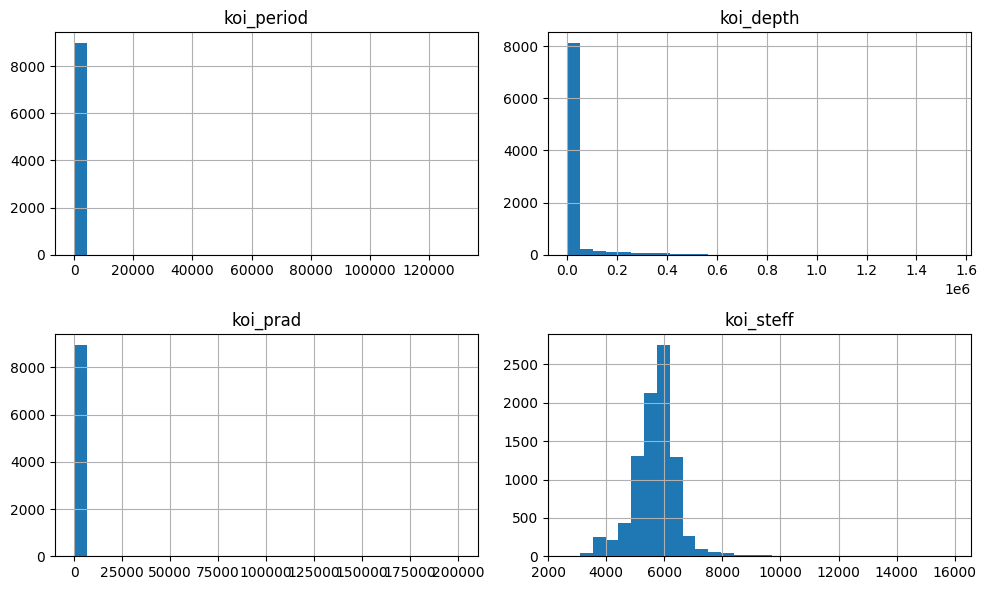

In [16]:
df[['koi_period','koi_depth','koi_prad','koi_steff']].hist(
    bins=30, figsize=(10,6)
)
plt.tight_layout()
plt.show()


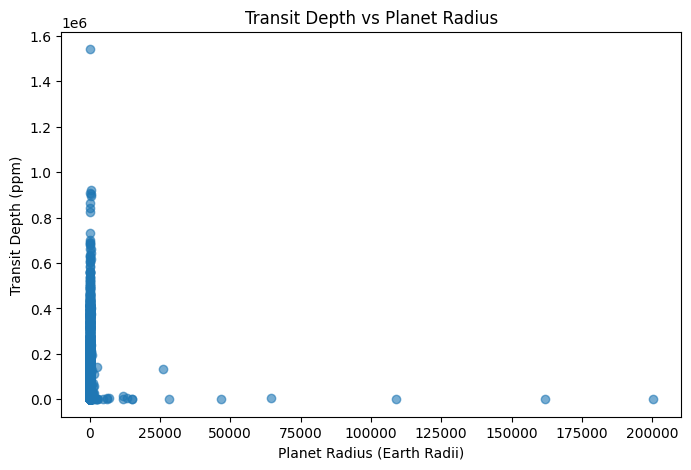

In [17]:
plot_df = df[['koi_prad', 'koi_depth']].dropna()

plt.figure(figsize=(8,5))

plt.scatter(
    plot_df['koi_prad'],
    plot_df['koi_depth'],
    alpha=0.6
)

plt.xlabel("Planet Radius (Earth Radii)")
plt.ylabel("Transit Depth (ppm)")
plt.title("Transit Depth vs Planet Radius")

plt.grid(False)   


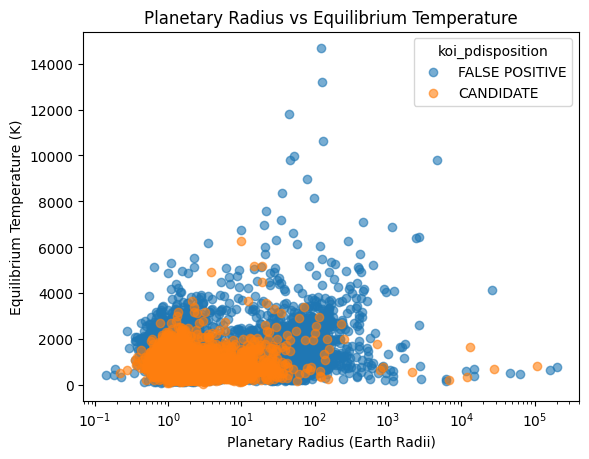

In [18]:
for label in sorted(df['koi_pdisposition'].unique(), reverse=True):
    subset = df[df['koi_pdisposition'] == label]
    plt.scatter(
        subset['koi_prad'],
        subset['koi_teq'],
        label=label,
        alpha=0.6
    )

    
plt.xlabel("Planetary Radius (Earth Radii)")
plt.ylabel("Equilibrium Temperature (K)")
plt.title("Planetary Radius vs Equilibrium Temperature")
plt.legend(title="koi_pdisposition")

plt.xscale('log')

plt.show()

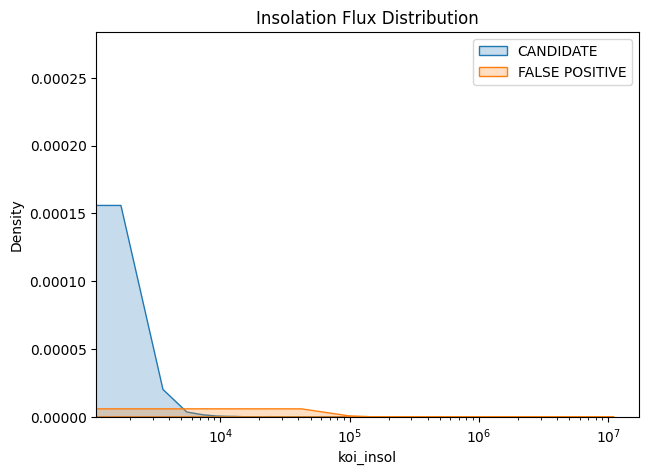

In [19]:
plt.figure(figsize=(7,5))

for label in df['koi_pdisposition'].unique():
    sns.kdeplot(
        df[df['koi_pdisposition'] == label]['koi_insol'],
        label=label,
        fill=True
    )

plt.xscale('log')
plt.title("Insolation Flux Distribution")
plt.legend()
plt.show()

In [20]:
bins = [0, 500, 1000, 1500, 2000, 3000, df['koi_teq'].max()]
labels = [
    "0–500",
    "500–1000",
    "1000–1500",
    "1500–2000",
    "2000–3000",
    ">3000"
]

df['Temperature_Class'] = pd.cut(
    df['koi_teq'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

temp_freq_table = df['Temperature_Class'].value_counts().sort_index()

distribution_table = pd.DataFrame({
    "Temperature Range (K)": temp_freq_table.index,
    "Frequency": temp_freq_table.values
})

print(distribution_table)

  Temperature Range (K)  Frequency
0                 0–500       1963
1              500–1000       3248
2             1000–1500       1878
3             1500–2000        960
4             2000–3000        687
5                 >3000        249


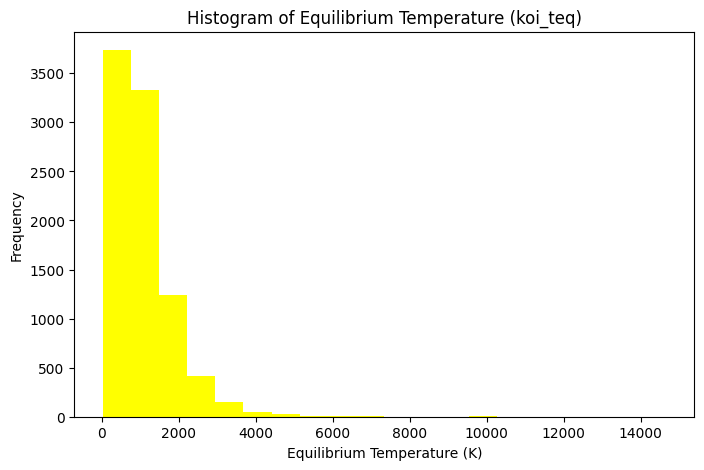

In [21]:
temps = df['koi_teq'].dropna()

plt.figure(figsize=(8,5))

plt.hist(temps, bins=20,color='yellow')

plt.xlabel("Equilibrium Temperature (K)")
plt.ylabel("Frequency")
plt.title("Histogram of Equilibrium Temperature (koi_teq)")
plt.grid(False)

plt.show()

In [22]:
X = X.select_dtypes(include=['int64', 'float64'])

### **Train-Test Split**


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

In [24]:
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [25]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss',
        n_estimators=200,
        max_depth=6
    ),

    "LightGBM": LGBMClassifier(
        random_state=42,
        n_estimators=200,
        max_depth=-1,
        class_weight='balanced'
    ),

    "CatBoost": CatBoostClassifier(
        random_state=42,
        verbose=0,
        n_estimators=200,
        depth=8
    )
}

### **Model-Training and Evaluation**

In [26]:
results = []

for name, model in models.items():

    cv_score = cross_val_score(
        model, X_train, y_train, 
        cv=5, 
        scoring='f1_weighted'
    ).mean()

 
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "CV F1-score": cv_score,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1-score": f1_score(y_test, y_pred, average='weighted')
    })

[LightGBM] [Info] Number of positive: 2818, number of negative: 2932
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001676 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 8425
[LightGBM] [Info] Number of data points in the train set: 5750, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Info] Number of positive: 2818, number of negative: 2932
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001763 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8426
[LightGBM] [Info] Number of data points in the train set: 5750, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGB

### **Model Performance Comparison**


In [27]:
results_df = pd.DataFrame(results)
print("\nMODEL PERFORMANCE COMPARISON\n")
print(results_df)


MODEL PERFORMANCE COMPARISON

           Model  CV F1-score  Accuracy  Precision    Recall  F1-score
0  Random Forest     0.848439  0.850306   0.850389  0.850306  0.850271
1        XGBoost     0.854285  0.851976   0.851976  0.851976  0.851976
2       LightGBM     0.858324  0.860879   0.860901  0.860879  0.860863
3       CatBoost     0.854015  0.868114   0.868304  0.868114  0.868067


### **Confusion Matrix for each Model**

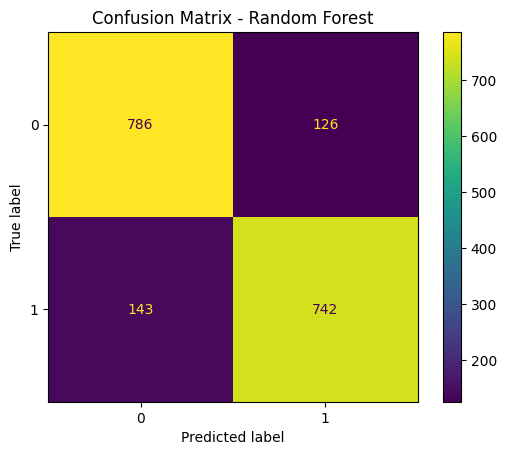

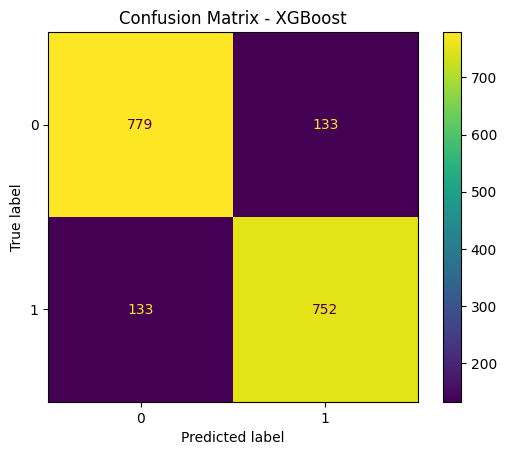

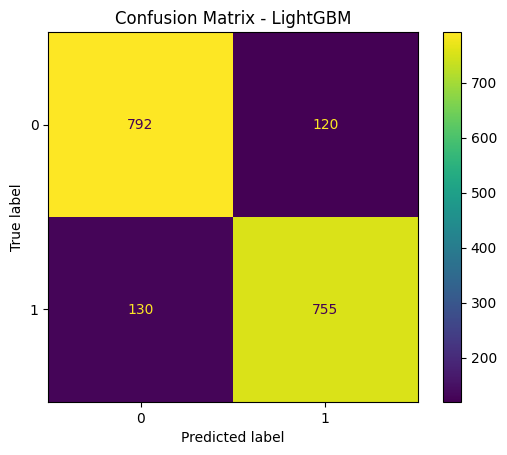

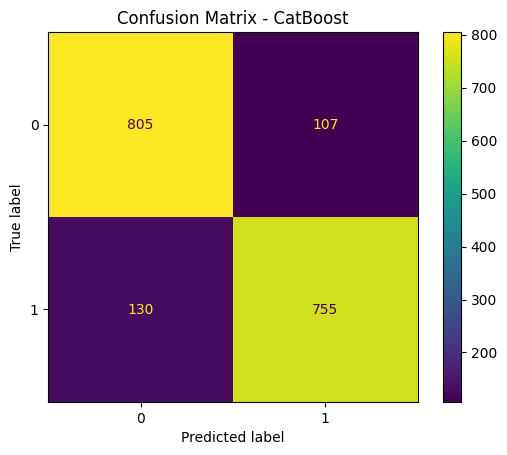

In [28]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

### **Classification Report**

In [29]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\nClassification Report – {name}\n")
    print(classification_report(y_test, y_pred))


Classification Report – Random Forest

              precision    recall  f1-score   support

           0       0.85      0.86      0.85       912
           1       0.85      0.84      0.85       885

    accuracy                           0.85      1797
   macro avg       0.85      0.85      0.85      1797
weighted avg       0.85      0.85      0.85      1797


Classification Report – XGBoost

              precision    recall  f1-score   support

           0       0.85      0.85      0.85       912
           1       0.85      0.85      0.85       885

    accuracy                           0.85      1797
   macro avg       0.85      0.85      0.85      1797
weighted avg       0.85      0.85      0.85      1797


Classification Report – LightGBM

              precision    recall  f1-score   support

           0       0.86      0.87      0.86       912
           1       0.86      0.85      0.86       885

    accuracy                           0.86      1797
   macro avg       

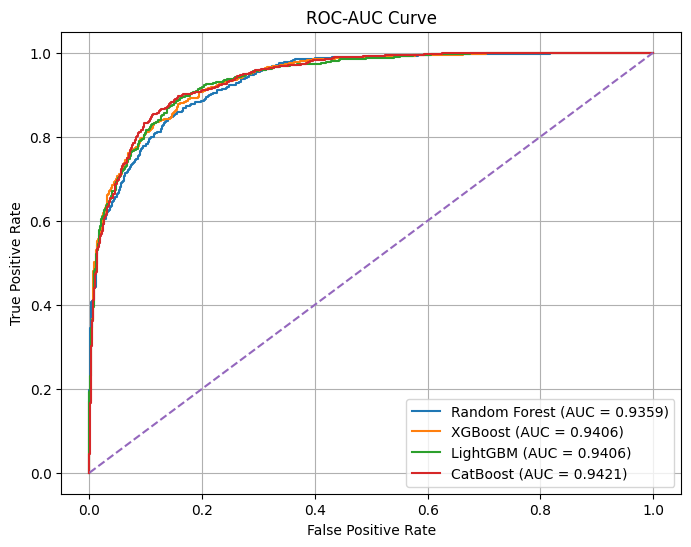

In [30]:
plt.figure(figsize=(8,6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()
plt.grid()

plt.show()

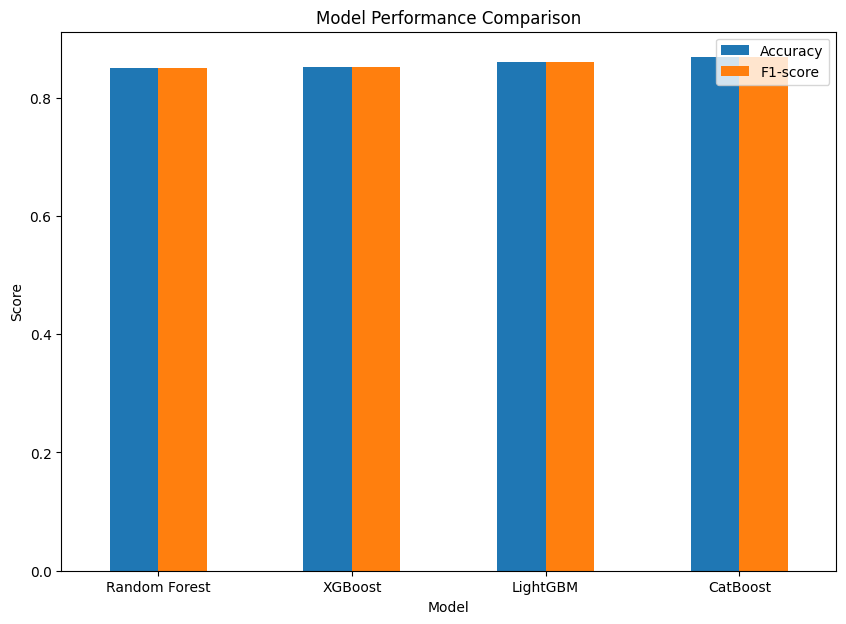

In [31]:
results_df.set_index("Model")[["Accuracy", "F1-score"]].plot(
    kind="bar",
    figsize=(10,7)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

### **HYBRID MODEL 0F Random Forest + XGBOOST + LightGBM + CatBoost**

In [32]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    random_state=42
)

cat_model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    verbose=0,        
    random_state=42
)

hybrid_model = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('xgb', xgb_model),
        ('lgbm', lgbm_model),
        ('cat', cat_model)  
    ],
    voting='soft'   
)

hybrid_model.fit(X_train, y_train)

y_pred = hybrid_model.predict(X_test)

[LightGBM] [Info] Number of positive: 3523, number of negative: 3665
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001953 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8442
[LightGBM] [Info] Number of data points in the train set: 7188, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.490122 -> initscore=-0.039515
[LightGBM] [Info] Start training from score -0.039515


In [33]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8636616583194212
Precision: 0.8611738148984198
Recall: 0.8621468926553673
F1 Score: 0.8616600790513834


Confusion Matrix:
 [[789 123]
 [122 763]]


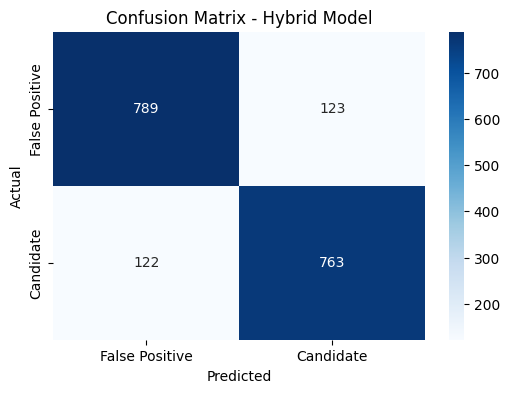

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.87      0.87       912
           1       0.86      0.86      0.86       885

    accuracy                           0.86      1797
   macro avg       0.86      0.86      0.86      1797
weighted avg       0.86      0.86      0.86      1797



In [34]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["False Positive", "Candidate"],
            yticklabels=["False Positive", "Candidate"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Hybrid Model")
plt.show()


report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

[LightGBM] [Info] Number of positive: 3523, number of negative: 3665
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001524 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8442
[LightGBM] [Info] Number of data points in the train set: 7188, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.490122 -> initscore=-0.039515
[LightGBM] [Info] Start training from score -0.039515


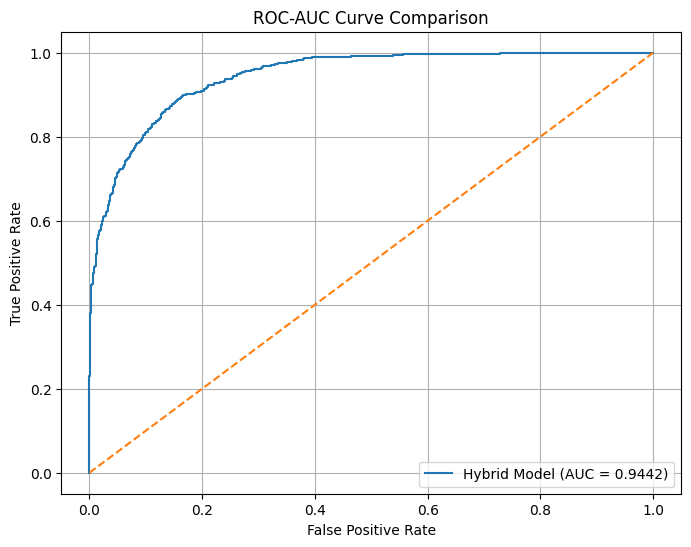

In [35]:
hybrid_model.fit(X_train, y_train)

plt.figure(figsize=(8,6))

models = {
    "Hybrid Model": hybrid_model
}

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve Comparison")
plt.legend()
plt.grid()

plt.show()

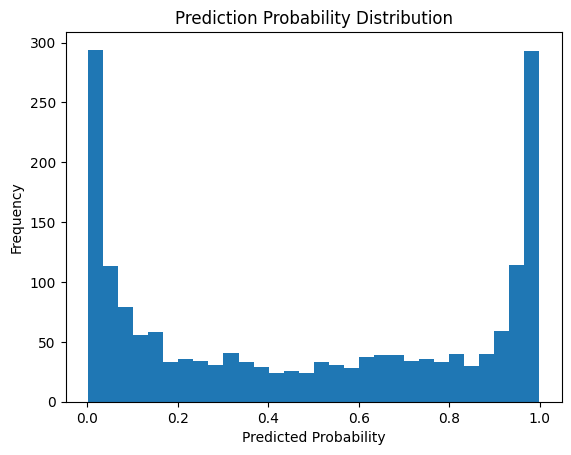

In [36]:
y_prob = hybrid_model.predict_proba(X_test)[:, 1]

plt.hist(y_prob, bins=30)

plt.title("Prediction Probability Distribution")
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.show()